# Lecture 6: Gradient Descent and Types of Gradient Descent

**Audience:** B.Tech, Semester 5  
**Class mode:** concept → predict → run → interpret  
**Notebook goal:** understand the optimizer's movement, not memorize plotting code.

> **Core story:** The loss surface is the terrain. The gradient tells us the local uphill direction. Gradient descent steps in the opposite direction. The learning rate controls the step size. Batch, SGD, and mini-batch differ only in how much data is used to estimate each step.


## Learning outcomes

By the end, you should be able to:

- interpret convex and non-convex loss surfaces in 2D and 3D;
- explain and derive the update $\theta_{t+1}=\theta_t-\eta\nabla J(\theta_t)$;
- predict what happens when the learning rate is too small or too large;
- distinguish Batch GD, SGD, and Mini-batch GD;
- explain why batch sizes such as 8, 16, and 32 are common—but not compulsory.

### Vocabulary used throughout

- **Parameter / weight:** a number learned by the model.
- **Loss:** one number measuring model error; lower is better.
- **Gradient:** vector of partial derivatives (local slopes).
- **Update:** one change to the parameters.
- **Epoch:** one complete pass through the training dataset.


In [ ]:
# Run this setup cell once.
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

np.random.seed(7)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {
    "blue": "#2563EB",
    "orange": "#F97316",
    "green": "#16A34A",
    "red": "#DC2626",
    "purple": "#7C3AED",
    "gray": "#64748B",
}

def check_activity(submitted, activity_key):
    # Return True/False for each response without displaying the answer key.
    checks = []
    for value, expected_fingerprint in zip(submitted, activity_key):
        try:
            token = f"{float(value):.6f}"
            fingerprint = hashlib.sha256(token.encode()).hexdigest()
            checks.append(fingerprint == expected_fingerprint)
        except (TypeError, ValueError):
            checks.append(False)
    return checks

print("Setup complete.")


Setup complete.


## STOP 1 — Convex surface

- Bowl-like: the line segment between any two points never lies below the graph.
- Every local minimum is a global minimum.
- A convex function need not have a unique minimum; **strict** convexity gives uniqueness.

**Predict before running:** If we start anywhere on the U-shaped curve and always move downhill, where should we finish?


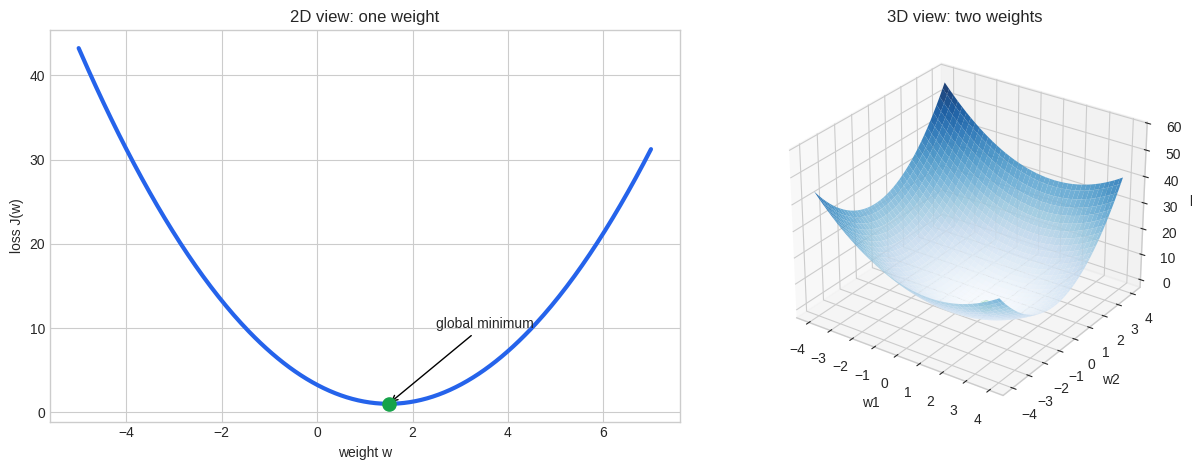

In [ ]:
# VISUALIZATION ONLY — focus on the two shapes, not the plotting commands.
w = np.linspace(-5, 7, 300)
loss_1d = (w - 1.5) ** 2 + 1

w1 = np.linspace(-4, 4, 120)
w2 = np.linspace(-4, 4, 120)
W1, W2 = np.meshgrid(w1, w2)
loss_2d = (W1 - 1) ** 2 + 1.5 * (W2 + 0.5) ** 2 + 1

fig = plt.figure(figsize=(13, 4.8))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(w, loss_1d, color=COLORS["blue"], linewidth=3)
ax1.scatter([1.5], [1], s=90, color=COLORS["green"], zorder=5)
ax1.annotate("global minimum", (1.5, 1), xytext=(2.5, 10),
             arrowprops={"arrowstyle": "->"})
ax1.set(title="2D view: one weight", xlabel="weight w", ylabel="loss J(w)")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(W1, W2, loss_2d, cmap=cm.Blues, alpha=0.9, linewidth=0)
ax2.scatter([1], [-0.5], [1], s=70, color=COLORS["green"])
ax2.set(title="3D view: two weights", xlabel="w1", ylabel="w2", zlabel="loss")
ax2.view_init(elev=28, azim=-55)

plt.tight_layout()
plt.show()


## STOP 2 — Non-convex surface

- Contains multiple valleys, flat regions, ridges, and saddle points.
- A **local minimum** is best only in a neighbourhood; a **global minimum** is best over the whole domain.
- Deep-network objectives are usually non-convex.

**Predict before running:** Could two different starting points finish in different valleys?


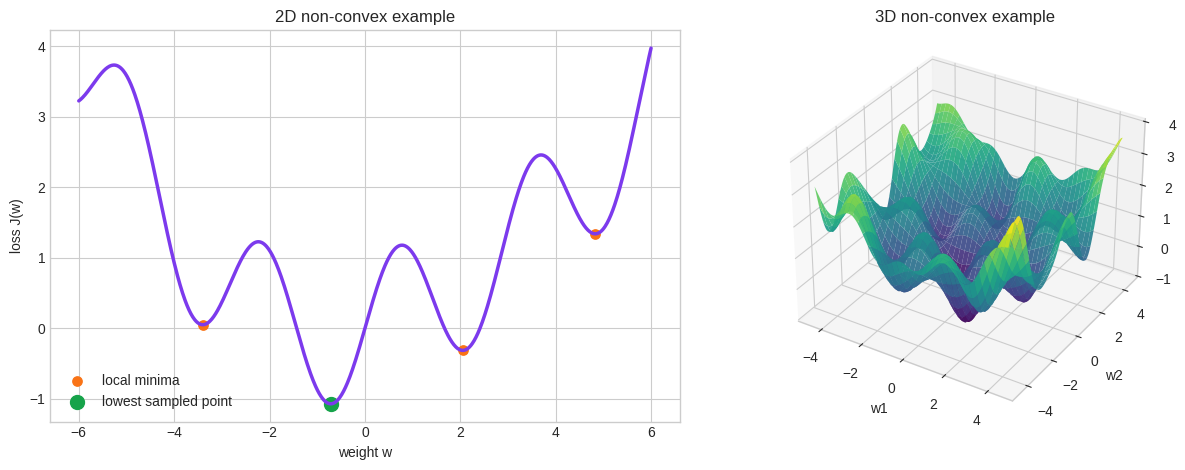

In [ ]:
# VISUALIZATION ONLY — the waves create several valleys.
w = np.linspace(-6, 6, 900)
nonconvex_1d = 0.10 * w**2 + np.sin(2.2 * w) + 0.25 * np.sin(0.7 * w)

candidate = np.where(
    (nonconvex_1d[1:-1] < nonconvex_1d[:-2]) &
    (nonconvex_1d[1:-1] < nonconvex_1d[2:])
)[0] + 1
global_index = np.argmin(nonconvex_1d)

w1 = np.linspace(-4.5, 4.5, 160)
w2 = np.linspace(-4.5, 4.5, 160)
W1, W2 = np.meshgrid(w1, w2)
nonconvex_2d = (
    0.08 * (W1**2 + W2**2)
    + np.sin(1.7 * W1) * np.cos(1.7 * W2)
    + 0.25 * np.sin(0.65 * W1 * W2)
)

fig = plt.figure(figsize=(13, 4.8))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(w, nonconvex_1d, color=COLORS["purple"], linewidth=2.5)
ax1.scatter(w[candidate], nonconvex_1d[candidate], color=COLORS["orange"],
            s=45, label="local minima")
ax1.scatter([w[global_index]], [nonconvex_1d[global_index]],
            color=COLORS["green"], s=100, label="lowest sampled point")
ax1.set(title="2D non-convex example", xlabel="weight w", ylabel="loss J(w)")
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(W1, W2, nonconvex_2d, cmap=cm.viridis,
                 alpha=0.92, linewidth=0, antialiased=True)
ax2.set(title="3D non-convex example", xlabel="w1", ylabel="w2", zlabel="loss")
ax2.view_init(elev=32, azim=-58)

plt.tight_layout()
plt.show()


## What determines the shape of a loss surface?

- **Model and parameterization:** linear model vs. multilayer network
- **Nonlinear activations:** ReLU, sigmoid, tanh, etc.
- **Interactions among weights:** changing one weight changes how other layers behave
- **Loss function:** MSE, cross-entropy, margin loss, etc.
- **Training data:** feature values, labels, noise, imbalance, and sample size
- **Regularization:** L1/L2 penalties add terms to the objective

Deep networks become non-convex mainly because nonlinear layers are composed and weights interact. **Having many weights alone does not prove non-convexity:** linear regression with MSE remains convex even with many weights.

> Practical goal: reduce training loss to a useful low value. On a convex objective, a suitable GD procedure can reach a global minimum. On a non-convex neural-network objective, ordinary GD does **not** guarantee the global minimum.


## STUDENT TODO 1 — Loss-surface detective (3 minutes)

**Work in pairs. Agree on all three choices before running the checker.**

1. On the 3D loss plot, the two horizontal axes represent:  
   **1** = two training examples  **2** = two model parameters
2. A non-convex objective means:  
   **1** = training is impossible  **2** = several valleys/saddles may exist
3. “A model has many weights, so its loss must be non-convex”:  
   **1** = always true  **2** = not necessarily true

Enter only `1` or `2` in the next cell. The checker gives a score, not the answers.


In [ ]:
# STUDENT TODO 1 — replace None with 1 or 2.
student_choices_1 = [2, 2, 2]

activity_key_1 = [
    "2a05d3b7c73b9f96c197e3a3c10dd8060d6eb939e47af3c420b1a8c85594fa70",
    "2a05d3b7c73b9f96c197e3a3c10dd8060d6eb939e47af3c420b1a8c85594fa70",
    "2a05d3b7c73b9f96c197e3a3c10dd8060d6eb939e47af3c420b1a8c85594fa70",
]

if None in student_choices_1:
    print("Complete all three choices, then run the cell again.")
else:
    checks = check_activity(student_choices_1, activity_key_1)
    revisit = [number for number, is_correct in enumerate(checks, start=1) if not is_correct]
    print(f"Score: {sum(checks)}/3")
    print("Revisit question(s):", revisit if revisit else "none — explain why to your partner")


Score: 3/3
Revisit question(s): none — explain why to your partner


---
# 2. Gradient Descent (GD)

The gradient points in the direction of **steepest local increase**. Therefore, the negative gradient points toward steepest local decrease.

the update is:

$$\boxed{\theta_{t+1}=\theta_t-\eta\nabla J(\theta_t)}$$

- subtract because the gradient is uphill;
- $\eta$ is the learning rate (step-size scale);
- recompute the gradient after every update.


## STOP 3 — One update by hand

Use $J(w)=(w-3)^2$. Then $\frac{dJ}{dw}=2(w-3)$.

At $w=-2$, is the derivative positive or negative? After subtracting it, should $w$ move left or right?


In [ ]:
# it is the entire update rule in Python.
def loss(w):
    return (w - 3) ** 2

def gradient(w):
    return 2 * (w - 3)

w_old = -2.0
learning_rate = 0.10

grad = gradient(w_old)
w_new = w_old - learning_rate * grad

print("old weight:", w_old)
print("gradient:  ", grad)
print("new weight:", w_new)
print("old loss:  ", loss(w_old))
print("new loss:  ", loss(w_new))


old weight: -2.0
gradient:   -10.0
new weight: -1.0
old loss:   25.0
new loss:   16.0


## STOP 4 — Repeated GD updates on a U-shaped curve

Watch three things:

1. the gradient is recomputed at the current weight;
2. steps become smaller near the minimum because the slope becomes smaller;
3. the U-shaped loss curve stays fixed—the parameter moves on it.


final weight: 2.9031
final loss:   0.009387


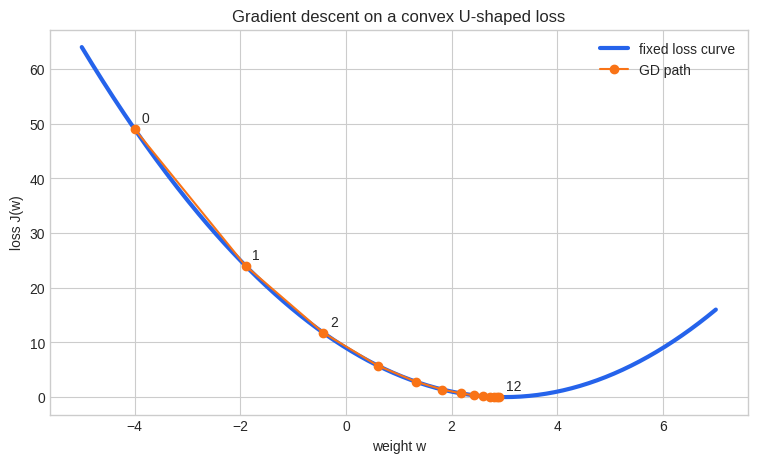

In [ ]:
#  the plotting part only displays its result.
w = -4.0
learning_rate = 0.15
steps = 12

weights = [w]
losses = [loss(w)]

for step in range(steps):
    w = w - learning_rate * gradient(w)
    weights.append(w)
    losses.append(loss(w))

print("final weight:", round(w, 4))
print("final loss:  ", round(loss(w), 6))

grid = np.linspace(-5, 7, 300)
plt.figure(figsize=(9, 5))
plt.plot(grid, loss(grid), linewidth=3, color=COLORS["blue"], label="fixed loss curve")
plt.plot(weights, losses, "o-", color=COLORS["orange"], label="GD path")
for i, (x_value, y_value) in enumerate(zip(weights, losses)):
    if i in (0, 1, 2, len(weights) - 1):
        plt.annotate(str(i), (x_value, y_value), xytext=(5, 5), textcoords="offset points")
plt.xlabel("weight w")
plt.ylabel("loss J(w)")
plt.title("Gradient descent on a convex U-shaped loss")
plt.legend()
plt.show()


## STUDENT TODO 2 — Perform one GD update (4 minutes)

Use $J(w)=(w-3)^2$, starting weight $w=-1$, and learning rate $\eta=0.20$.

On paper, calculate:

1. the gradient $2(w-3)$;
2. the new weight $w_{new}=w-\eta\times gradient$;
3. the new loss $J(w_{new})$.

Then enter your three numbers below. You may use decimals.


In [ ]:
# STUDENT TODO 2 — replace None with your calculated numbers.
student_gradient_2 = None
student_new_weight_2 = None
student_new_loss_2 = None

student_work_2 = [student_gradient_2, student_new_weight_2, student_new_loss_2]
activity_key_2 = [
    "e4af69f99347d6df8933a911ef495d12795b65f102c3884b15400b703946f247",
    "4390e03ef925c93679adb851c8a7112bbf959b4e5cdcc55407b4f816224057ac",
    "7ce150122c1bebe72d56626ffd83be42515ac085336e6ab8758412e99d5260ec",
]

if None in student_work_2:
    print("Enter the gradient, new weight, and new loss; then run again.")
else:
    checks = check_activity(student_work_2, activity_key_2)
    revisit = [number for number, is_correct in enumerate(checks, start=1) if not is_correct]
    print(f"Score: {sum(checks)}/3")
    print("Revisit step(s):", revisit if revisit else "none — now explain the minus sign")


Enter the gradient, new weight, and new loss; then run again.


### What GD does—and does not promise

- GD is a **local**, iterative method; it reads the slope where it currently stands.
- For a smooth convex objective and a suitable learning rate, it can converge to a global minimum.
- For a non-convex objective, the result can depend on initialization and optimization details.
- A nearly zero gradient can occur at a minimum, maximum, saddle, or flat plateau.
- Training normally stops using a step limit, small improvement, small gradient, or validation-based rule.


---
# 3. Learning rate (LR)

The learning rate $\eta$ scales the update:

$$\text{step}=\eta\times\text{gradient}$$

- **too small:** correct direction, very slow progress
- **useful range:** rapid, stable convergence
- **large:** crosses the valley and oscillates
- **too large:** loss can explode

> **Crucial distinction:** changing $\eta$ does not reshape the loss curve. It changes only the sequence of weights visited on that curve.


## STOP 5 — Same curve, different learning rates

Before running, predict which path will be slow, fast, oscillating, or divergent.


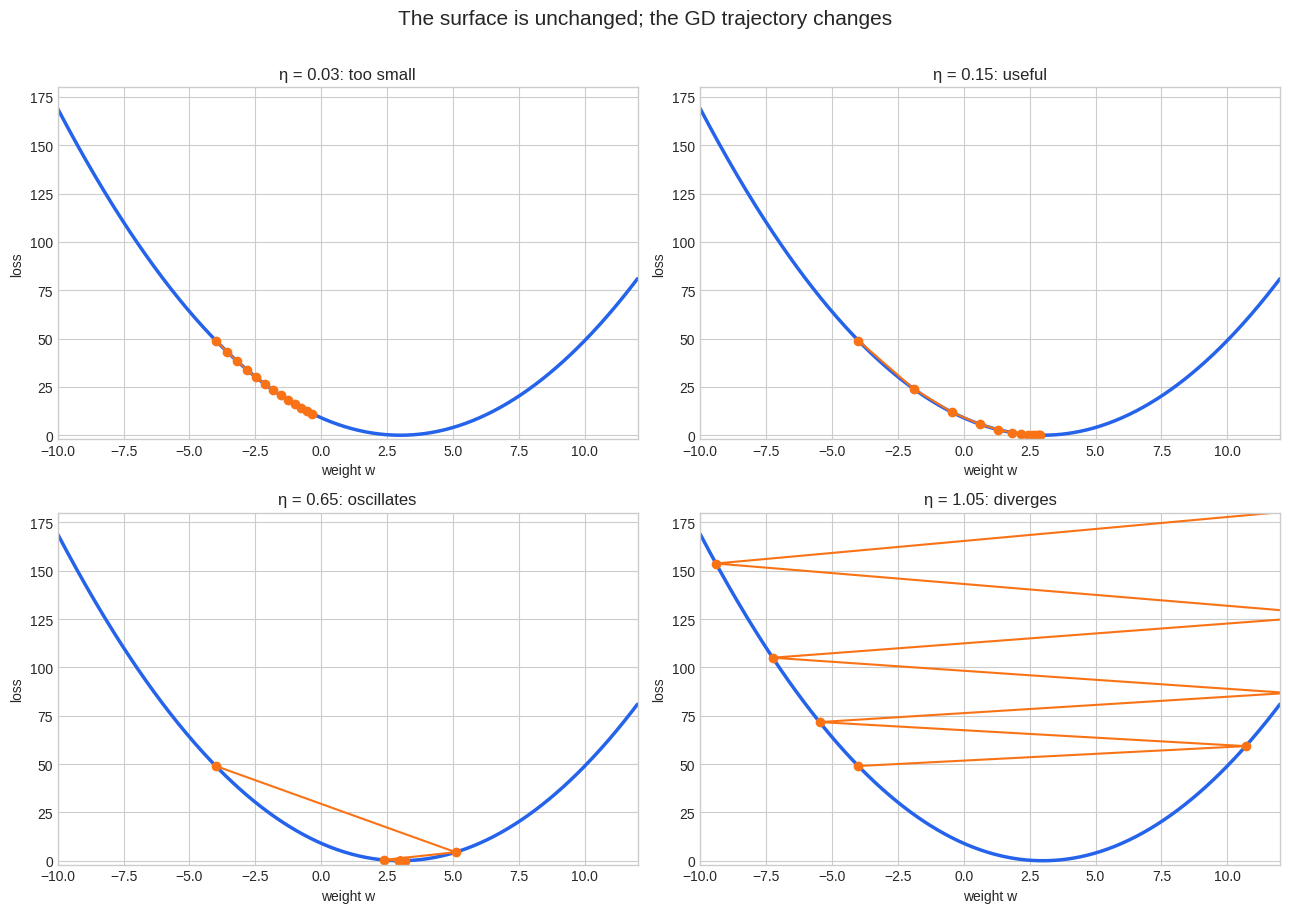

In [ ]:
# VISUALIZATION ONLY — every panel uses the same loss curve and start point.
def run_gd(lr, start=-4.0, steps=12):
    path = [start]
    w = start
    for _ in range(steps):
        w = w - lr * gradient(w)
        path.append(w)
    return np.array(path)

learning_rates = [0.03, 0.15, 0.65, 1.05]
labels = ["too small", "useful", "oscillates", "diverges"]
grid = np.linspace(-10, 12, 500)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, lr, label in zip(axes.ravel(), learning_rates, labels):
    path = run_gd(lr)
    finite = np.abs(path) < 40
    ax.plot(grid, loss(grid), linewidth=2.5, color=COLORS["blue"])
    ax.plot(path[finite], loss(path[finite]), "o-", color=COLORS["orange"])
    ax.set_xlim(-10, 12)
    ax.set_ylim(-2, 180)
    ax.set_title(f"η = {lr}: {label}")
    ax.set_xlabel("weight w")
    ax.set_ylabel("loss")

fig.suptitle("The surface is unchanged; the GD trajectory changes", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()


## LR playground (Google Colab form control)

Change the slider value, rerun the cell, and observe the path. Try values near **0.01**, **0.15**, **0.80**, **1.00**, and **1.10**.

For this particular quadratic $J(w)=(w-3)^2$, values $0<\eta<1$ converge; $\eta=1$ produces a same-distance sign flip; and $\eta>1$ diverges. This boundary is specific to this function—not a universal LR rule.


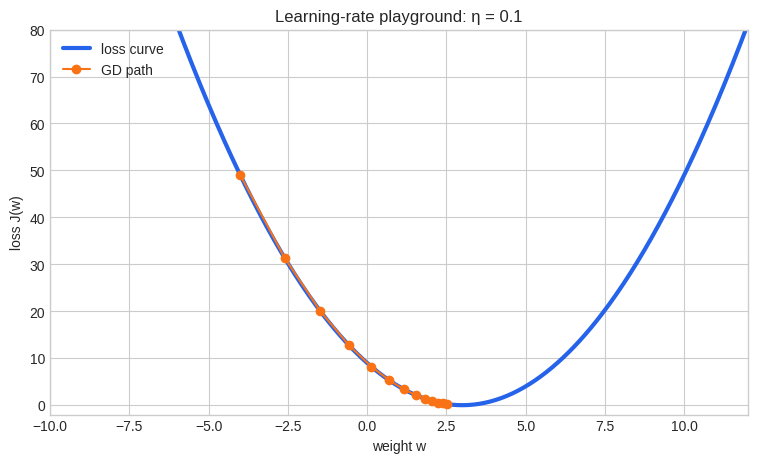

visited weights: [-4.    -2.6   -1.48  -0.584  0.133  0.706  1.165  1.532  1.826  2.06
  2.248  2.399  2.519]


In [ ]:
LEARNING_RATE = 0.1 #@param {type:"slider", min:0.01, max:1.20, step:0.01}
START_WEIGHT = -4.0 #@param {type:"number"}
NUMBER_OF_STEPS = 12 #@param {type:"integer"}

path = run_gd(LEARNING_RATE, START_WEIGHT, NUMBER_OF_STEPS)
visible = np.abs(path) < 100

grid = np.linspace(-10, 12, 500)
plt.figure(figsize=(9, 5))
plt.plot(grid, loss(grid), linewidth=3, color=COLORS["blue"], label="loss curve")
plt.plot(path[visible], loss(path[visible]), "o-", color=COLORS["orange"], label="GD path")
plt.xlim(-10, 12)
plt.ylim(-2, min(250, max(80, float(np.max(loss(path[visible]))) * 1.1)))
plt.xlabel("weight w")
plt.ylabel("loss J(w)")
plt.title(f"Learning-rate playground: η = {LEARNING_RATE}")
plt.legend()
plt.show()

print("visited weights:", np.round(path, 3))


## How do we choose a learning rate?

- There is no single best LR for every model and dataset.
- Try values on a logarithmic scale (for example $10^{-4},10^{-3},10^{-2},10^{-1}$).
- Run short experiments; monitor training and validation curves.
- If loss explodes or becomes NaN, lower the LR and check data/gradients.
- Optimizer, feature scaling, normalization, model depth, and batch size all affect a useful LR.

### Learning-rate decay

Start with larger steps, then use smaller steps for fine adjustment:

$$\eta_t=\eta_0\gamma^t,\qquad 0<\gamma<1$$

Common schedules: step decay, exponential decay, cosine decay, and warmup followed by decay. Decay helps refinement, but it cannot rescue a disastrously large starting LR.


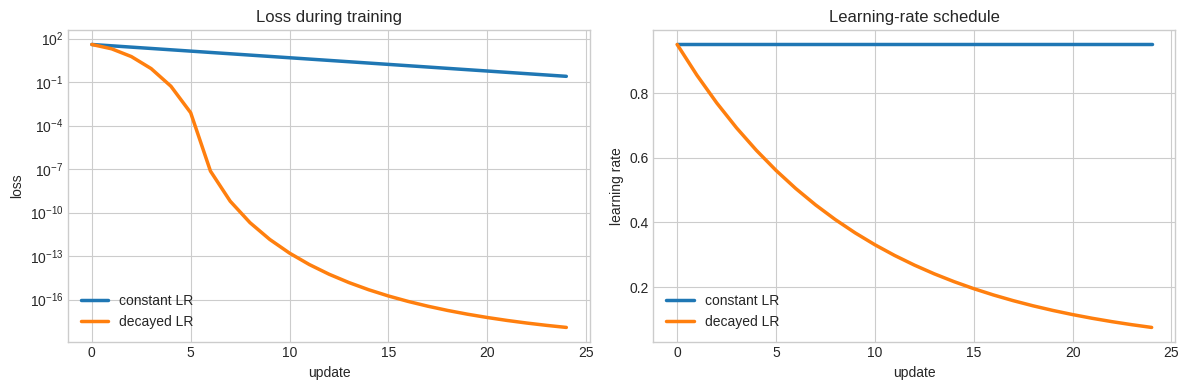

In [ ]:
#  — only the value of lr changes over time.
def train_with_schedule(use_decay):
    w = -4.0
    eta_0 = 0.95
    history = []

    for step in range(25):
        lr = eta_0 * (0.90 ** step) if use_decay else eta_0
        w = w - lr * gradient(w)
        history.append((step, lr, w, loss(w)))

    return np.array(history)

constant = train_with_schedule(use_decay=False)
decayed = train_with_schedule(use_decay=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(constant[:, 0], constant[:, 3], label="constant LR", linewidth=2.5)
axes[0].plot(decayed[:, 0], decayed[:, 3], label="decayed LR", linewidth=2.5)
axes[0].set(title="Loss during training", xlabel="update", ylabel="loss")
axes[0].set_yscale("log")
axes[0].legend()

axes[1].plot(constant[:, 0], constant[:, 1], label="constant LR", linewidth=2.5)
axes[1].plot(decayed[:, 0], decayed[:, 1], label="decayed LR", linewidth=2.5)
axes[1].set(title="Learning-rate schedule", xlabel="update", ylabel="learning rate")
axes[1].legend()
plt.tight_layout()
plt.show()


## STUDENT TODO 3 — Diagnose the learning rate (3 minutes)

Use the earlier plot for the same quadratic and classify each statement:

1. $\eta=0.03$: **1** = slow progress **2** = oscillates but converges **3** = diverges
2. $\eta=0.65$: **1** = slow progress **2** = oscillates but converges **3** = diverges
3. $\eta=1.05$: **1** = slow progress **2** = oscillates but converges **3** = diverges
4. Increasing $\eta$ makes the blue loss curve steeper: **1** = yes **2** = no

Decide individually, compare with a neighbour, and then run the checker.


In [ ]:
# STUDENT TODO 3 — enter one choice for each statement.
student_choices_3 = [None, None, None, None]

activity_key_3 = [
    "b42a73dadec1c669cf9f985d24d8be5e91e302c8b1941a91d30d5f278aa72fcf",
    "2a05d3b7c73b9f96c197e3a3c10dd8060d6eb939e47af3c420b1a8c85594fa70",
    "8291fe5714d2b2b756e8c8d67b61672203da76804bbe2d5d63a4110767fc51a1",
    "2a05d3b7c73b9f96c197e3a3c10dd8060d6eb939e47af3c420b1a8c85594fa70",
]

if None in student_choices_3:
    print("Complete all four choices, then run the cell again.")
else:
    checks = check_activity(student_choices_3, activity_key_3)
    revisit = [number for number, is_correct in enumerate(checks, start=1) if not is_correct]
    print(f"Score: {sum(checks)}/4")
    print("Revisit question(s):", revisit if revisit else "none — describe each trajectory")


Complete all four choices, then run the cell again.
